In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
df = pd.read_csv(
    "data.csv",
    header=None,
    encoding="1251",
    dtype=str
)

print(df.head())
print("Размер таблицы:", df.shape)


                               0            1                                                  2                                                  3  \
0                            NaN          NaN  11241000300120200001 Доля домашних хозяйств, и...  11241000300120200001 Доля домашних хозяйств, и...   
1                            NaN          NaN                                            2019 г.                                            2020 г.   
2           Российская Федерация          643                                               76,9                                                 80   
3  Центральный федеральный округ          030                                               78,7                                               81,7   
4           Белгородская область  14000000000                                               70,9                                               72,5   

                                                   4                                         

In [84]:
df.columns = [
    "Регион",
    "Код",
    "2019",
    "2020",
    "2021",
    "2022",
    "2023",
    "2024",
    "2025"
]

feature_cols = [
    "2019",
    "2020",
    "2021",
    "2022",
    "2023",
    "2024",
    "2025"
]

for col in feature_cols:
    df[col] = pd.to_numeric(
        df[col].str.replace(",", ".", regex=False),
        errors="coerce"
    )

display(df.head())
print(df.dtypes)

,Регион,Код,2019,2020,2021,2022,2023,2024,2025
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Российская Федерация,643,76.9,80.0,84.0,86.60,87.9,NaN,NaN
3,Центральный федеральный округ,030,78.7,81.7,85.8,87.90,88.5,91.6,93.3
4,Белгородская область,14000000000,70.9,72.5,78.7,78.09,79.2,87.4,91.0


Регион        str
Код           str
2019      float64
2020      float64
2021      float64
2022      float64
2023      float64
2024      float64
2025      float64
dtype: object


In [85]:
print("Количество строк:", len(df))
print("Количество регионов:", df["Регион"].nunique())

print("\nПропущенные значения:")
print(df[feature_cols].isnull().sum())

print("\nСтатистические характеристики:")
display(df[feature_cols].describe())

Количество строк: 100
Количество регионов: 98

Пропущенные значения:
2019    3
2020    3
2021    3
2022    3
2023    3
2024    3
2025    3
dtype: int64

Статистические характеристики:


,2019,2020,2021,2022,2023,2024,2025
count,97.000000,97.000000,97.000000,97.000000,97.000000,97.000000,97.000000
mean,76.302784,79.670825,83.416598,85.755361,87.376907,90.120515,90.749485
std,6.718757,6.407942,5.879164,5.895407,5.378170,4.387837,5.098981
min,64.700000,63.400000,72.000000,73.900000,75.000000,78.090000,72.200000
25%,71.090000,75.700000,79.200000,82.100000,83.200000,86.900000,86.900000
50%,76.900000,79.000000,82.700000,85.500000,87.600000,89.900000,91.400000
75%,79.500000,83.100000,87.300000,89.700000,91.000000,93.400000,93.700000
max,95.000000,95.400000,98.500000,99.100000,99.000000,99.400000,100.000000


In [87]:
regions = df["Регион"].copy()
X = df[feature_cols].copy()
X = X.fillna(X.median())
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [88]:
# KMeans
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)
labels_kmeans = kmeans.fit_predict(X_scaled)

# иерархическая кластеризация
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)
labels_hierarchical = hierarchical.fit_predict(X_scaled)

# DBSCAN
dbscan = DBSCAN(
    eps=1.0,
    min_samples=3
)
labels_dbscan = dbscan.fit_predict(X_scaled)

print("KMeans:", np.unique(labels_kmeans))
print("Agglomerative:", np.unique(labels_hierarchical))
print("DBSCAN:", np.unique(labels_dbscan))

KMeans: [0 1 2]
Agglomerative: [0 1 2]
DBSCAN: [-1  0  1  2]


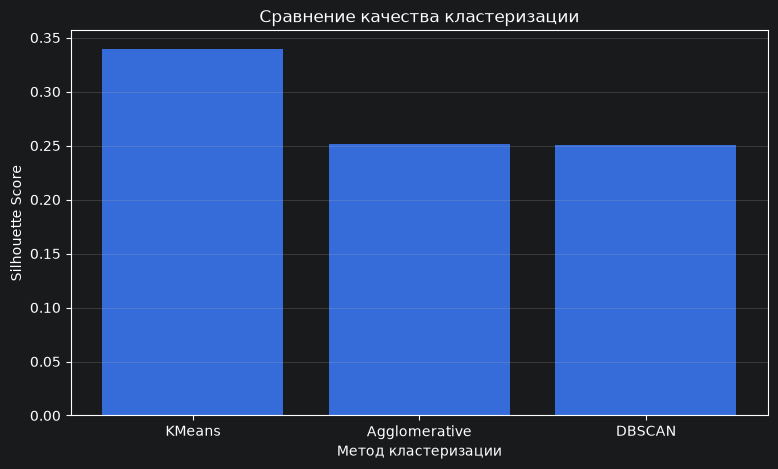

In [66]:
plot_data = results.dropna(subset=["Silhouette"])

plt.figure(figsize=(9, 5))

plt.bar(
    plot_data["Метод"],
    plot_data["Silhouette"]
)

plt.title("Сравнение качества кластеризации")
plt.xlabel("Метод кластеризации")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)

plt.show()

Объяснённая дисперсия: 87.53 %


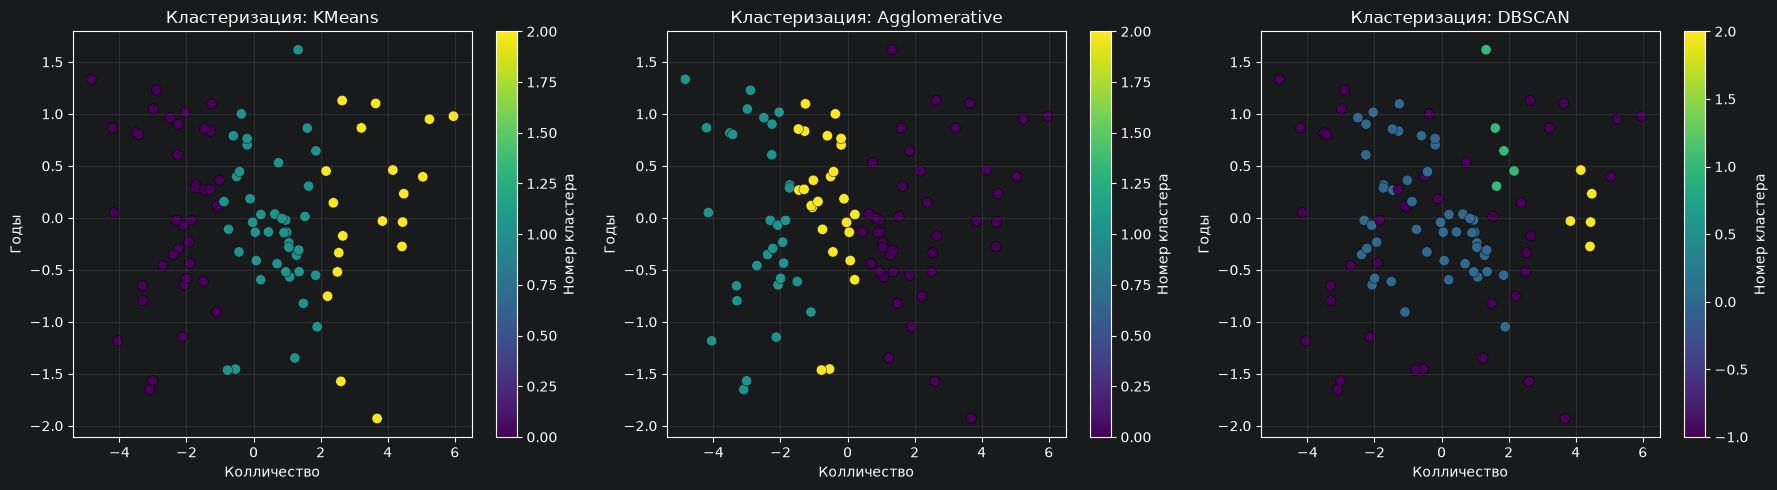

In [90]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(
    "Объяснённая дисперсия:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

models = {
    "KMeans": labels_kmeans,
    "Agglomerative": labels_hierarchical,
    "DBSCAN": labels_dbscan
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, labels) in zip(axes, models.items()):
    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="viridis",
        s=55,
        edgecolors="black",
        linewidths=0.3
    )

    ax.set_title(f"Кластеризация: {name}")
    ax.set_xlabel("Колличество")
    ax.set_ylabel("Годы")
    ax.grid(alpha=0.2)

    fig.colorbar(scatter, ax=ax, label="Номер кластера")

plt.tight_layout()
plt.show()